# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import signal

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

In [7]:
# Setting parameters 
N = 500
t = np.linspace(0, 1, N, endpoint=False)
signal_freq = 3.0
dt = t[1] - t[0]

# 1. The Signal
nonsinu_signal = signal.sawtooth(2 * np.pi * signal_freq * t)

# 2. The Magnitude of its Fourier Transform
signal_ft = np.fft.fft(nonsinu_signal)
freqs = np.fft.fftfreq(N, dt)
mag_ft = np.abs(signal_ft)

# 3. The Phase Information of the Transform (unwrapped)
phase_ft = np.angle(signal_ft)
phase_ft_unwrapped = np.unwrap(phase_ft) # comment this if we want it wrapped


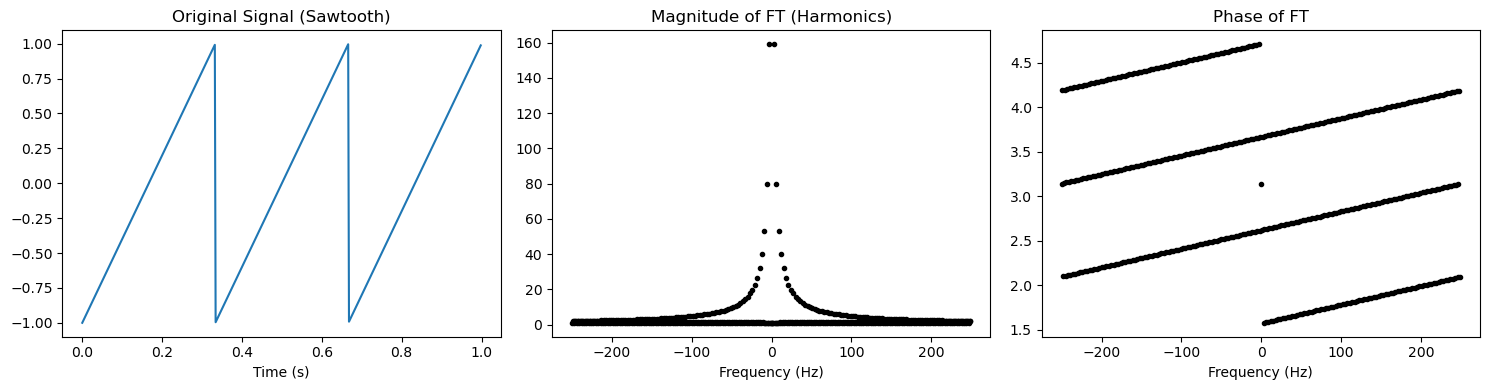

In [11]:
# Plotting into a 1x3 subplot 
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(t, nonsinu_signal)
ax[0].set_title("Original Signal (Sawtooth)")
ax[0].set_xlabel("Time (s)")

ax[1].plot(freqs, mag_ft, "k.")
ax[1].set_title("Magnitude of FT (Harmonics)")
ax[1].set_xlabel("Frequency (Hz)")

ax[2].plot(freqs, phase_ft_unwrapped, "k.") # Use phase_ft if we want wrapped
ax[2].set_title("Phase of FT")
ax[2].set_xlabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

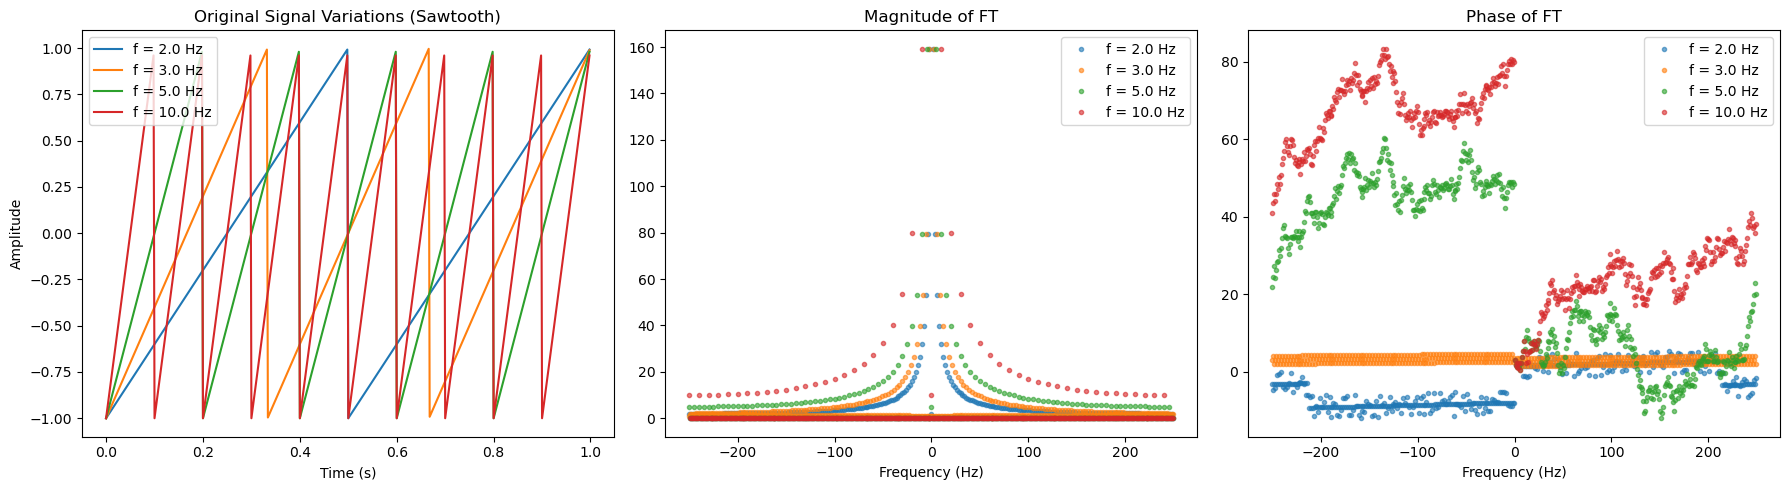

In [31]:
# Plotting using different frequency variations 
import numpy as np
import matplotlib.pyplot as plt
import math 
from scipy import signal 

# Setting parameters 
N = 500
t = np.linspace(0, 1, N, endpoint=False)
dt = t[1] - t[0]

# Defining frequency variations to explore 
signal_freq_var = [2.0, 3.0, 5.0, 10.0]

# Plotting into a 1x3 subplot
fig, ax = plt.subplots(1, 3, figsize=(18,5))

for f in signal_freq_var:
    # 1. The Signal, with its variations 
    nonsinu_signal = signal.sawtooth(2 * np.pi * f * t)

    # 2. The Magnitude of its Fourier Transform
    signal_ft = np.fft.fft(nonsinu_signal)
    freqs = np.fft.fftfreq(N, dt)
    mag_ft = np.abs(signal_ft)

    # 3. The Phase Information of the Transform (unwrapped)
    phase_ft = np.angle(signal_ft)
    phase_ft_unwrapped = np.unwrap(phase_ft) # comment this if we want it wrapped

    # Plotting the variations on the same axes for comparison
    ax[0].plot(t, nonsinu_signal, label=f'f = {f} Hz')
    ax[1].plot(freqs, mag_ft, ".", alpha=0.6, label=f'f = {f} Hz')
    ax[2].plot(freqs, phase_ft_unwrapped, ".", alpha=0.6, label=f'f = {f} Hz') # Use phase_ft if we want wrapped

# Formatting the subplots 
ax[0].set_title("Original Signal Variations (Sawtooth)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

ax[1].set_title("Magnitude of FT")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].legend()

ax[2].set_title("Phase of FT")
ax[2].set_xlabel("Frequency (Hz)")
ax[2].legend()

plt.tight_layout()
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


----
1. Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal

In [115]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

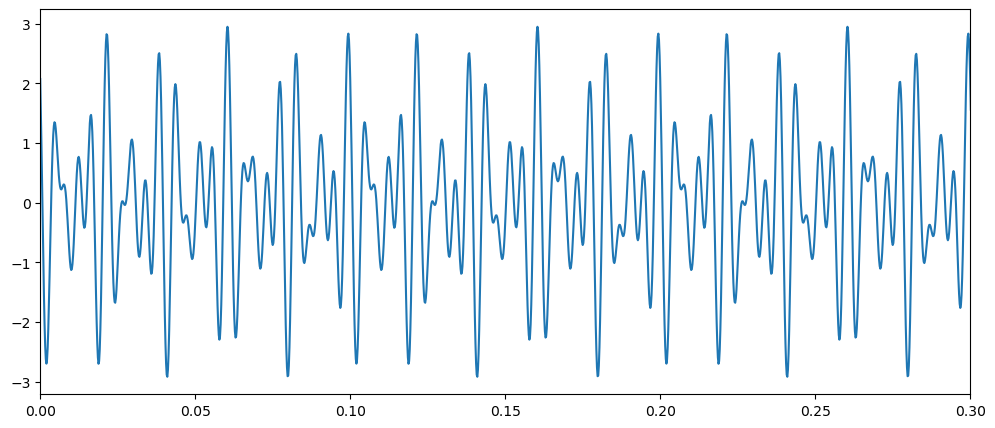

In [36]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

In [4]:
#FILL: Plot the fourier transform of the clean, original signal

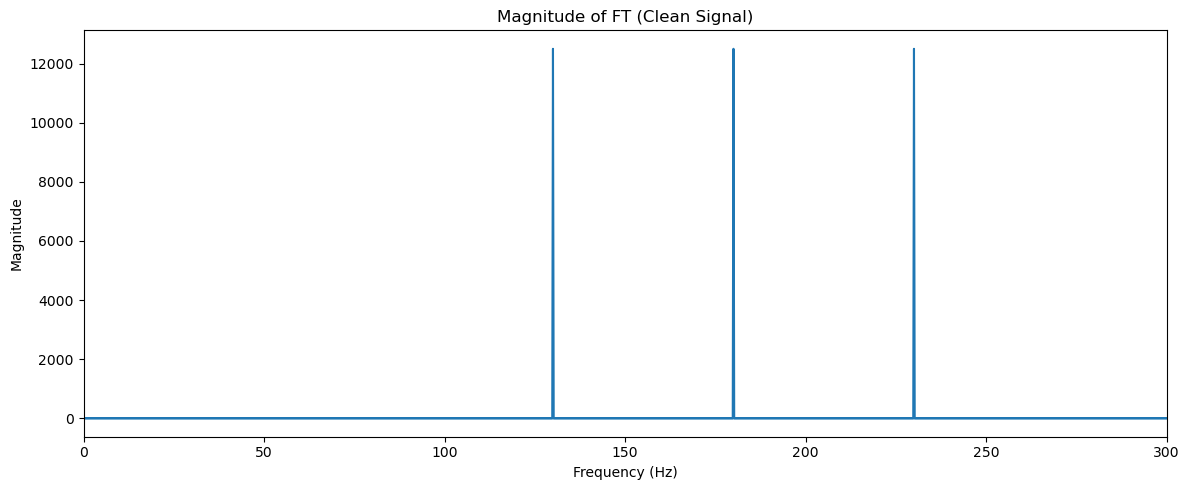

In [121]:
# Computing for the Fourier Transform of the clean, original signal
clean_ft = np.fft.fft(signal_original)
freqs = np.fft.fftfreq(N, dt)
mag_clean_ft = np.abs(clean_ft)

# Plotting
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(freqs, mag_clean_ft)
ax.set_title("Magnitude of FT (Clean Signal)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_xlim(0, 300)

plt.tight_layout()
plt.show()

2. Add noise (gaussian noise)

In [84]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point

#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

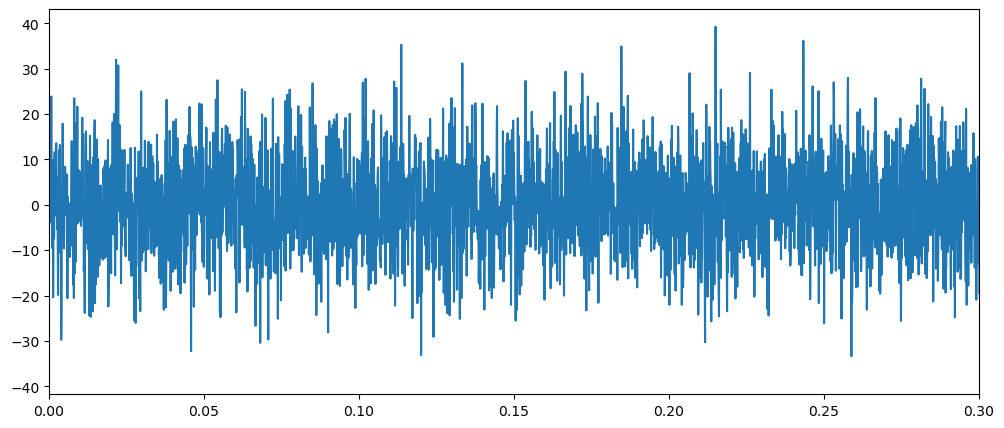

In [85]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

3. Add a window (Hann)

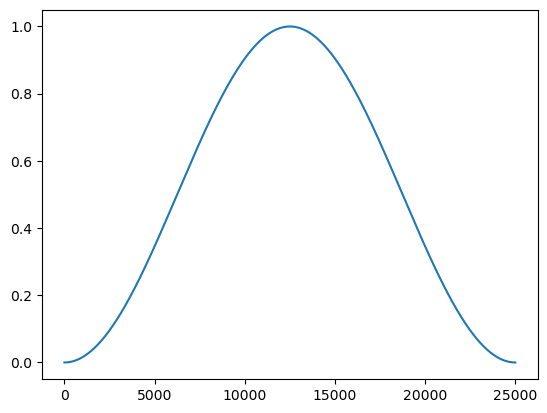

In [87]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [102]:
# Getting Fourier Transform of Hanning Window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

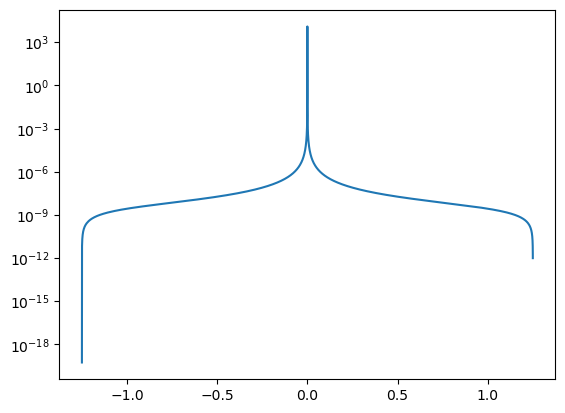

In [103]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [54]:
noisyFourier = np.fft.fft(noisy_data*window)

# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

4. Get fft of the noisy signal

In [11]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

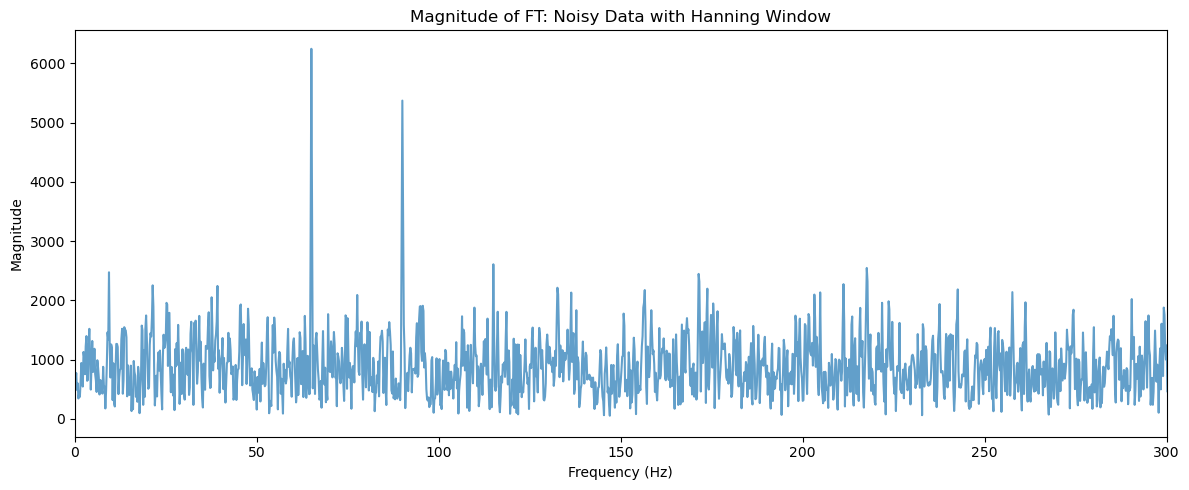

In [122]:
noisyFourier_mag = np.abs(np.fft.fftshift(noisyFourier)) 

fig, ax = plt.subplots(figsize=(12,5))

ax.plot(windowSigFreqs, noisyFourier_mag, alpha=0.7)
ax.set_title("Magnitude of FT: Noisy Data with Hanning Window")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_xlim(0, 300)

plt.tight_layout()
plt.show()

5. Filter frequencies below a threshold

In [12]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

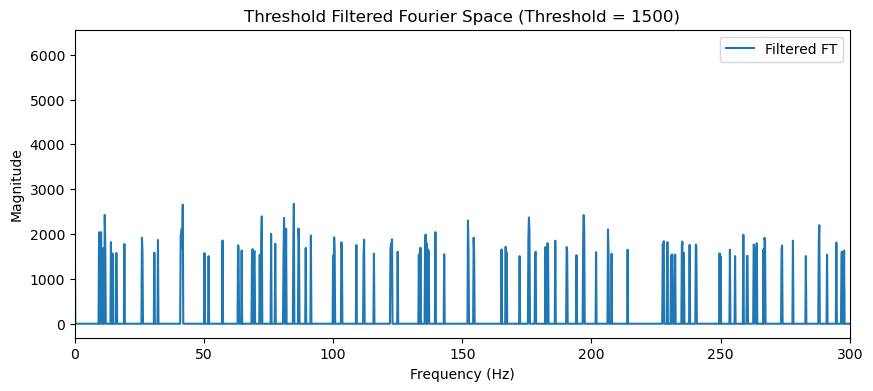

In [123]:
threshold = 1500

filtered_fft = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)
filtered_fft_mag = np.abs(filtered_fft)

# Plotting
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(windowSigFreqs, filtered_fft_mag, label='Filtered FT')
ax.set_title(f"Threshold Filtered Fourier Space (Threshold = {threshold})")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_xlim(0, 300)

ax.legend()
plt.show()

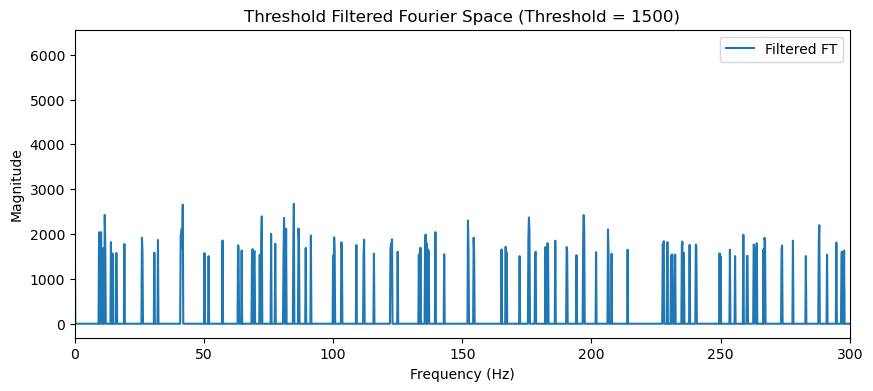

In [114]:
# STANDBY THIS IS AI
# Ensure your main lab parameters are active here:
N = 25000
dt = 0.0002

# Regenerate your frequency array with the correct main parameters
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

threshold = 1500
filtered_fft = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)
filtered_fft_mag = np.abs(filtered_fft)

# Plotting
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(windowSigFreqs, filtered_fft_mag, label='Filtered FT')
ax.set_title(f"Threshold Filtered Fourier Space (Threshold = {threshold})")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")

# Zoom in to your 130, 180, and 230 Hz signals
ax.set_xlim(0, 300)

ax.legend()
plt.show()

6. Get the inverse fft

In [13]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

In [130]:
recovered_signal = np.real(np.fft.ifft(filtered_fft))

7. Compare the result

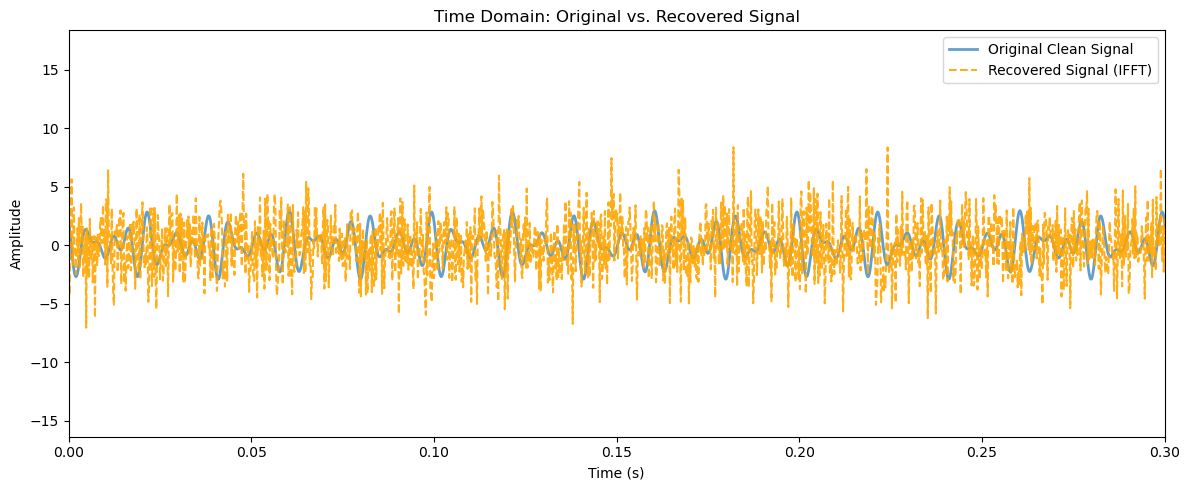

In [132]:
# Plotting the recovered signal
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(t_, signal_original, label='Original Clean Signal', alpha=0.7, linewidth=2)
ax.plot(t_, recovered_signal, label='Recovered Signal (IFFT)', linestyle='--', alpha=0.9, color='orange')

ax.set_title("Time Domain: Original vs. Recovered Signal")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, 0.3)  # Zoomed in to see the waveform overlay
ax.legend()

plt.tight_layout()
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

---
1. Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.

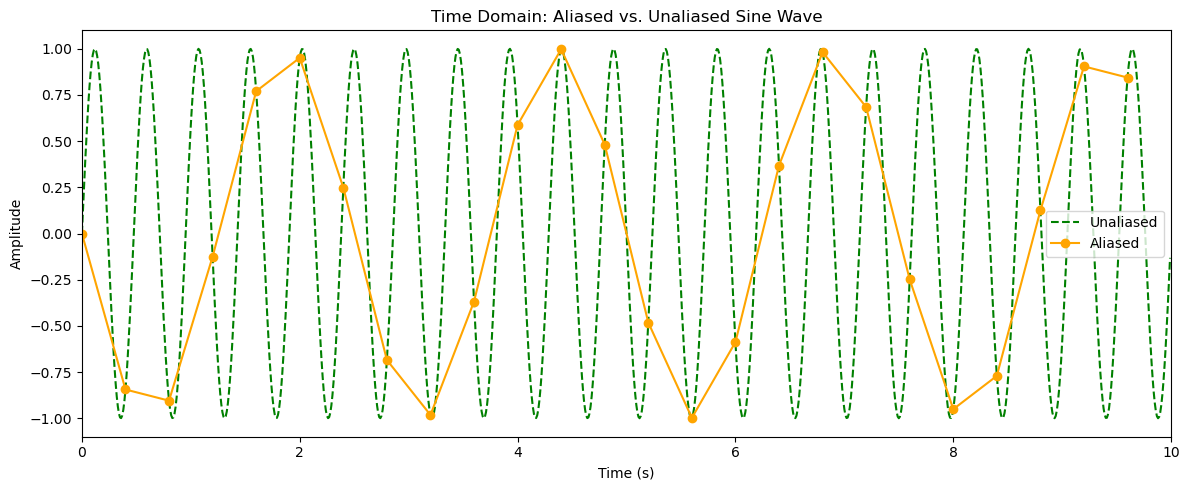

In [133]:
import numpy as np
import matplotlib.pyplot as plt
 
n_aliased = 25       
n_unaliased = 1000   
t = 10 # This is the total duration 
dt = t/n_aliased 
dt_un = t/n_unaliased

t_aliased = np.arange(n_aliased) * dt
t_unaliased = np.arange(n_unaliased) * dt_un

freq = 2.1  # Signal frequency 

def cont_signal(freq, time):
    return np.sin(2 * np.pi * freq * time)

discrete_signal = cont_signal(freq, t_aliased)
discrete_unaliased = cont_signal(freq, t_unaliased)

# Plotting
fig, ax = plt.subplots(figsize=(12,5))

ax.plot(t_unaliased, discrete_unaliased, color="green", linestyle='--', label="Unaliased")
ax.plot(t_aliased, discrete_signal, color="orange", marker='o', label="Aliased")
ax.set_xlim(0, 10)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Time Domain: Aliased vs. Unaliased Sine Wave")
ax.legend()

plt.tight_layout()
plt.show()

2. Get their fourier transforms. Are they the same?
3. Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.

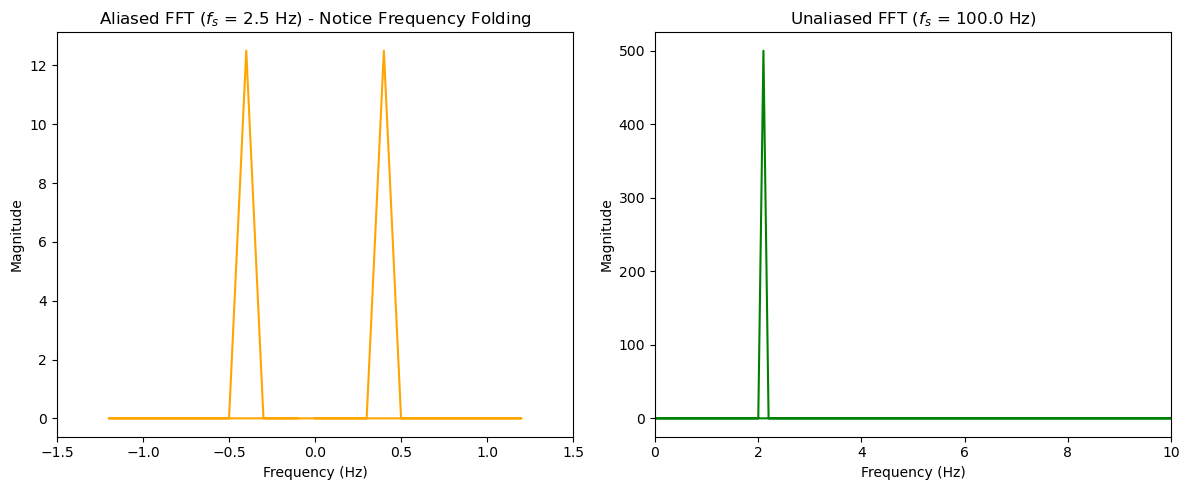

In [143]:
# Getting Fourier Transforms of Aliased and Unaliased
ft_aliased = np.fft.fft(discrete_signal)
freqs_aliased = np.fft.fftfreq(n_aliased, dt)
mag_aliased = np.abs(ft_aliased)

ft_unaliased = np.fft.fft(discrete_unaliased)
freqs_unaliased = np.fft.fftfreq(n_unaliased, dt_un)
mag_unaliased = np.abs(ft_unaliased)

# Plotting into a 1x2 subplot for comparison
fig, ax = plt.subplots(1, 2, figsize=(12,5))

ax[0].plot(freqs_aliased, mag_aliased, color="orange")
ax[0].set_title(f"Aliased FFT ($f_s$ = {1/dt:.1f} Hz) - Notice Frequency Folding")
ax[0].set_ylabel("Magnitude")
ax[0].set_xlabel("Frequency (Hz)")
ax[0].set_xlim(-1.5, 1.5)

ax[1].plot(freqs_unaliased, mag_unaliased, color="green")
ax[1].set_title(f"Unaliased FFT ($f_s$ = {1/dt_un:.1f} Hz)")
ax[1].set_ylabel("Magnitude")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_xlim(0, 10)

plt.tight_layout()
plt.show()

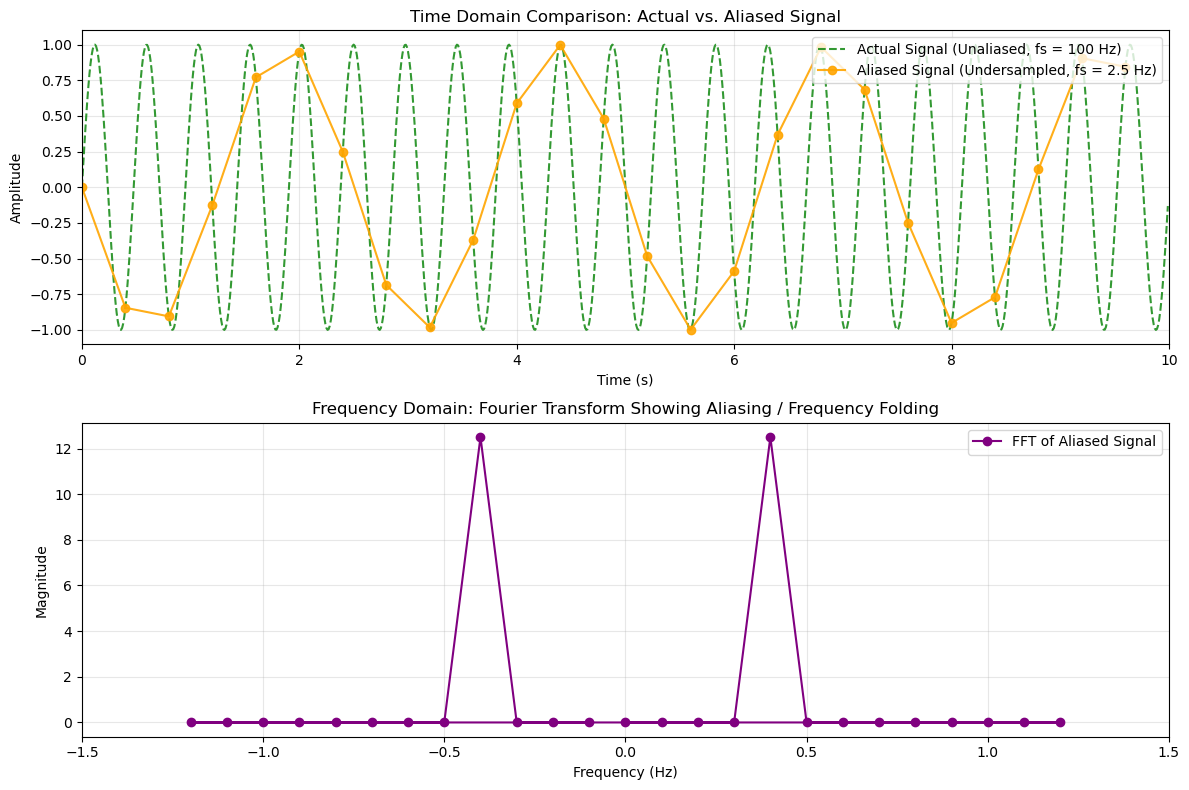

In [142]:
# This is AI
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Parameters ---
n_aliased = 25       
n_unaliased = 1000   
t_max = 10.0
dt = t_max / n_aliased
dt_un = t_max / n_unaliased

t_aliased = np.arange(n_aliased) * dt
t_unaliased = np.arange(n_unaliased) * dt_un

freq = 2.1  # Signal frequency (Hz)

def cont_signal(freq, time):
    return np.sin(2 * np.pi * freq * time)

# Generate time-domain signals
signal_unaliased = cont_signal(freq, t_unaliased)
signal_aliased = cont_signal(freq, t_aliased)

# --- 2. Compute the Fourier Transform of the Aliased Signal ---
fft_aliased = np.fft.fft(signal_aliased)
freqs_aliased = np.fft.fftfreq(n_aliased, dt)
fft_aliased_mag = np.abs(fft_aliased)

# --- 3. Plotting Everything Together ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# Subplot 1: Time Domain (Unaliased vs. Aliased)
ax1.plot(t_unaliased, signal_unaliased, color="green", linestyle='--', label="Actual Signal (Unaliased, fs = 100 Hz)", alpha=0.8)
ax1.plot(t_aliased, signal_aliased, color="orange", marker='o', linestyle='-', label="Aliased Signal (Undersampled, fs = 2.5 Hz)", alpha=0.9)
ax1.set_title("Time Domain Comparison: Actual vs. Aliased Signal")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Amplitude")
ax1.set_xlim(0, t_max)
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Subplot 2: Frequency Domain (FFT of the Aliased Signal)
ax2.plot(freqs_aliased, fft_aliased_mag, color="purple", marker='o', linestyle='-', label="FFT of Aliased Signal")
ax2.set_title("Frequency Domain: Fourier Transform Showing Aliasing / Frequency Folding")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude")
ax2.set_xlim(-1.5, 1.5)  # Zoomed in near baseband to see the folded frequency peak
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

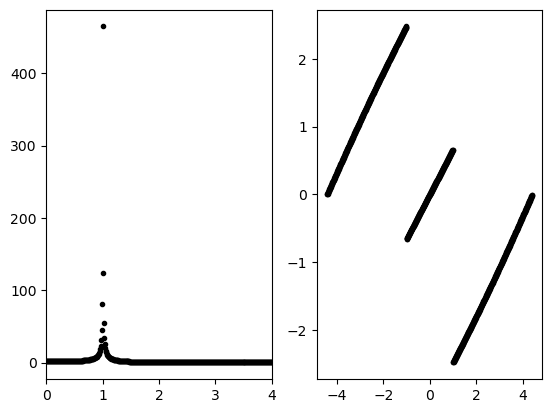

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

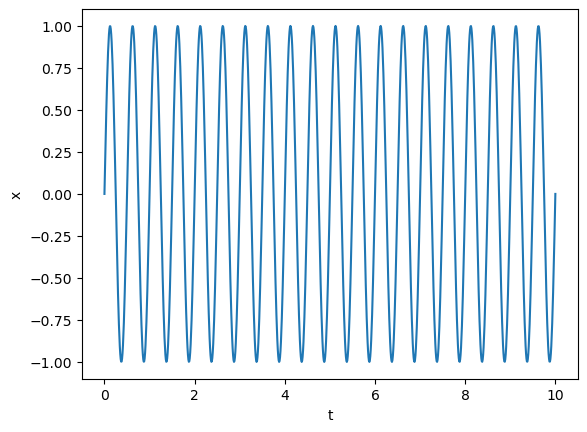

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

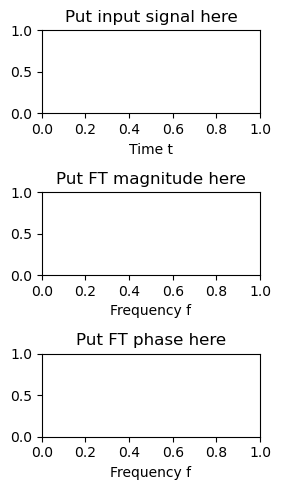

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

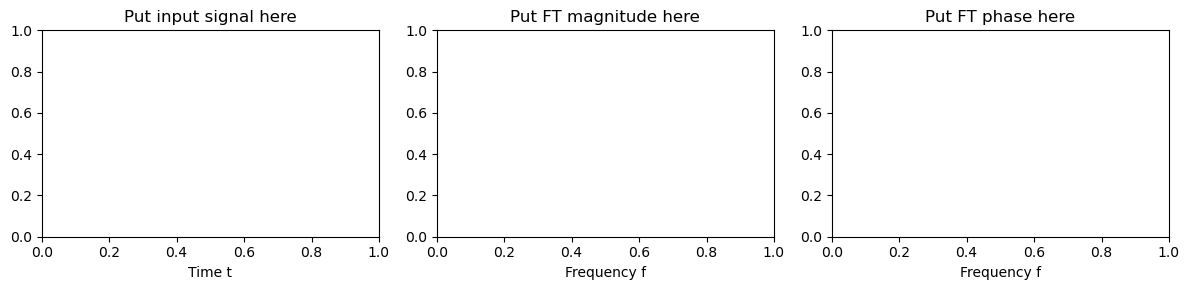

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

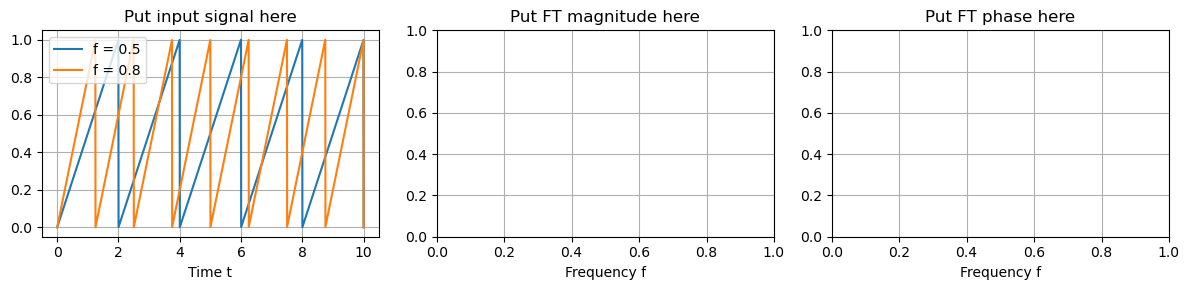

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



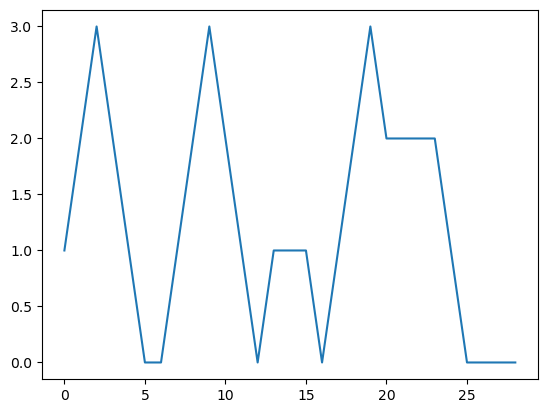

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

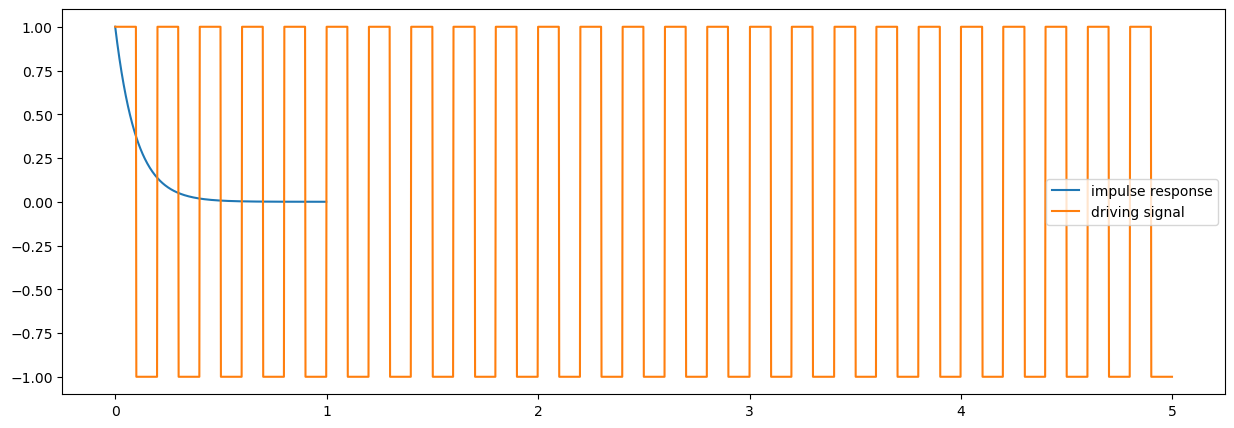

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

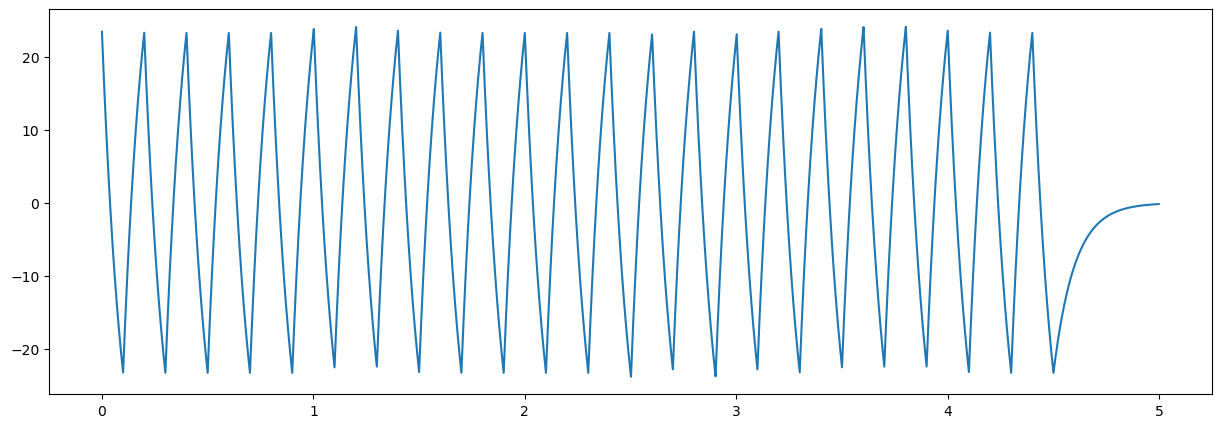

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

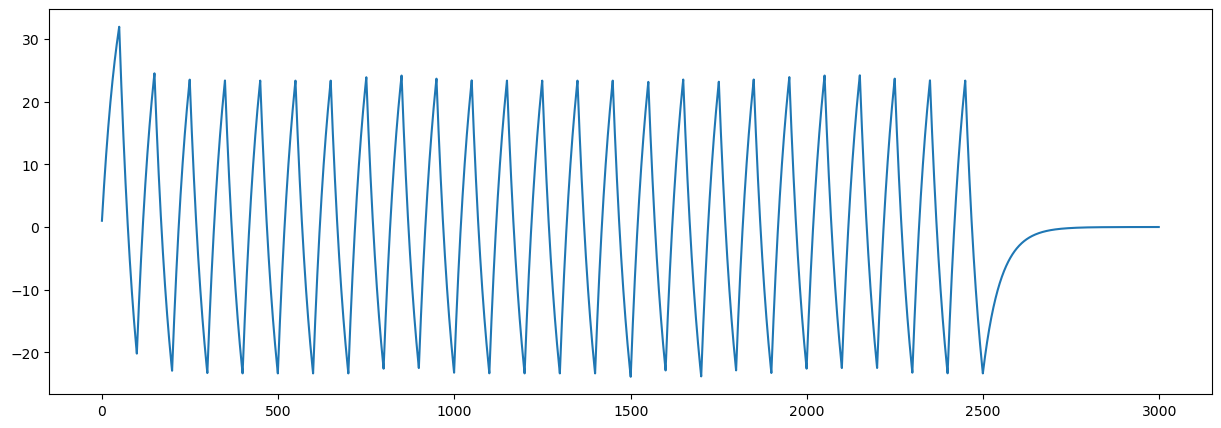

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)